# Exploratory Data Analysis (EDA)

In the second stage of the machine learning research pipeline, we undertake EDA in two forms. First a statistical exploration to identify any skewness in data, the range of values, any missing values, and duplicates and unique values. Through visual exploration we can identify outliers, and visual patterns. 

## Case-Study 01: Malta International Airport passenger movements

### Data acquisition

In [1]:
# Loading libraries
import pandas as pd
import os.path as osp

In [2]:
# Load the dataset
df = pd.read_csv(osp.join('..', 'data', 'mia', 'miaPassengers.txt'), sep='\t')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        19 non-null     int64
 1   passengers  19 non-null     int64
dtypes: int64(2)
memory usage: 436.0 bytes


In [3]:
# Preview the start of the data
df.head()

,year,passengers
0,2005,2397049
1,2006,2696034
2,2007,2974501
3,2008,3109868
4,2009,2918664


In [4]:
# Preview the end of the data
df.tail()

,year,passengers
14,2019,7310289
15,2020,1748050
16,2021,2540335
17,2022,5851079
18,2023,7803042


This dataset appears to be a complete dataset (no missing values), made up of 19 observations/rows and 2 variables/columns. These are both 64-bit integers taking a total of 436 bytes of memory. It also appears to be a temporal dataset with a range of years from 2005 till 2023, focusing on passenger movements in the Malta International Airport. Therefore this appears to be a labelled dataset, making it a supervised machine learning problem, with the focus being on predicting future movements. Moving forward we should focus on:
1. Confirming the range of values
2. Confirm any data issues such as missing values or duplicates
3. Visualise the dataset to observe any patterns prior to data modelling

### Exploratory Data Analysis

In [5]:
# Statistical EDA
df.describe()

,year,passengers
count,19.000000,1.900000e+01
mean,2014.000000,4.244323e+06
std,5.627314,1.773922e+06
min,2005.000000,1.748050e+06
25%,2009.500000,2.946582e+06
50%,2014.000000,3.649938e+06
75%,2018.500000,5.465575e+06
max,2023.000000,7.803042e+06


From this output we can confirm that the dataset is actually sorted ranging from 2005 till 2023. We also confirm that there are no values such as 0 or -ve used to represent missing data.

In [6]:
# Checking for data issues
# Check for nulls
df.isna().sum()

year          0
passengers    0
dtype: int64

In [7]:
# Checking for duplicated rows
df.duplicated().sum()

np.int64(0)

Following these last 2 checks we can confirm that till now there does not appear to be any issues with the data, no missing no duplicates

In [9]:
# Visual exploration, some additional libraries are needed
import matplotlib.pyplot as plt
import seaborn as sns

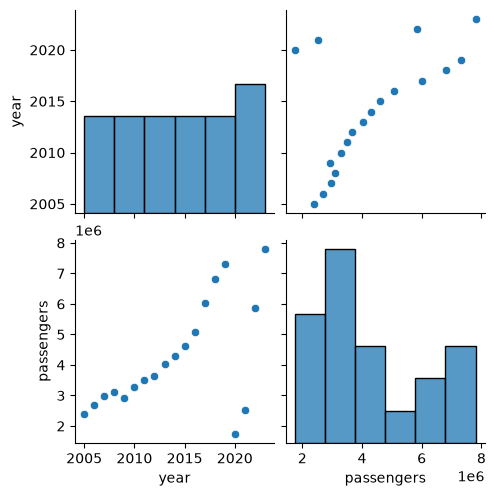

In [10]:
# Starting with a pairplot
sns.pairplot(data=df)

The seaborn pairplot has the benefit of provide a quick visual for all variables in the form of histograms, then scatterplots for every pairing of all variables. Note that the visual is a flipped mirror image across the diagonal. The downside of this visual is that you will get a lot of visuals that might be unneccessary, as well as it might be crammed. Yet it provides a quick visual glance at the data.

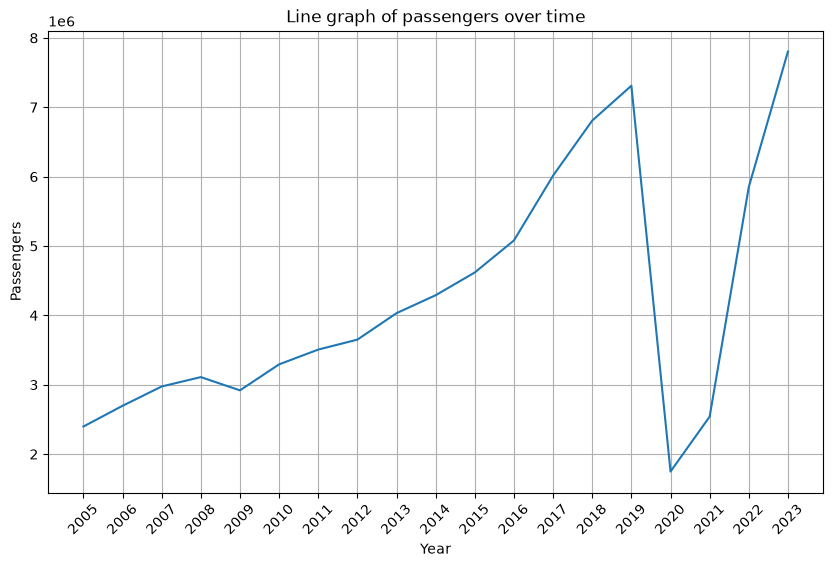

In [13]:
# Generating a line chart
plt.figure(figsize=(10, 6))
plt.plot(df['year'], df['passengers'])
plt.title('Line graph of passengers over time')
plt.xlabel('Year')
plt.ylabel('Passengers')
plt.xticks(df['year'], rotation=45)
plt.grid(True)
plt.show()

From this visual we can observe that there are a number of events that merit further investiagtion:
1. The 2008, and subsequent years, dip. Possibly attributed to the 2008 global recession. The market appears to have taken till 2013 to recover fully.
2. The radical steep growth in movement from 2016, or thereof. An investigation on whether there was a key investment or changes thereabout. 
3. The 2019/2020 dip, which is most likely to the global COVID-19 pandemic. We observe that the market started to recover in 2021 and recovered very quickly, yet not to pre 2020 levels by 2023. 

Recommendation for moving forward, to undertake predictions post 2025, it is recommended to obtain additional information, in particualar movements from 2024 and 2025. 

## Case-Study 02: Shopping mall dataset

This case-study explores additional EDA techniques using the Shopping mall dataset obtained from [this Git Repository](https://ganpat-patel-012.github.io/Customer-Segmentation-Exopsys-Data-Labs-Internship/).

### Data acquisition

In [4]:
# Import libraries
import pandas as pd
import os.path as osp

In [5]:
#Load dataset
df = pd.read_csv(osp.join('..', 'data', 'mall', 'customers.csv'))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [6]:
#Preview data
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


From the df.info we observe that this is a complete dataset, made up of 5 variables and 200 observations. Initially it appears that there are no missing information, we still need to confirm if a specific value such as 0 or 'null' is used to represent missing data. We suspect that the dataset might be sorted first by income then indexed. CustomerID being the index is irrelevant. We also note that the variable names are too long and contain symbols as well as numbers which make it challenging in coding.

This is a case of an unsupervised machine learning dataset, whereby there is no labelled data, such that forecasting or classification is not possible. Here we can undertake clustering (similarity), yet the answer is not provided. 

The plan:
1. Rename columns to more meaningful manner
2. Specify list of usable variables
3. Undertake EDA

In [8]:
# Rename columns
df = df.rename(columns = {"CustomerID": "id",
                      "Gender": "gender",
                      "Age": "age",
                      "Annual Income (k$)": "income",
                      "Spending Score (1-100)": "score"})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      200 non-null    int64
 1   gender  200 non-null    str  
 2   age     200 non-null    int64
 3   income  200 non-null    int64
 4   score   200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [9]:
vars = ['gender', 'age', 'income', 'score']
vars

['gender', 'age', 'income', 'score']

### Exploratory Data Analysis

In [10]:
#Statistical analysis
df[vars].describe()

,age,income,score
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [11]:
#Explicit null check
df[vars].isna().sum()

gender    0
age       0
income    0
score     0
dtype: int64

In [12]:
# Check for duplicates
df[vars].duplicated().sum()

np.int64(0)

In [13]:
# Checking the range of values of non numeric variables
df['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [14]:
df['gender'].value_counts()

gender
Female    112
Male       88
Name: count, dtype: int64

In [15]:
df['gender'].value_counts(normalize=True)

gender
Female    0.56
Male      0.44
Name: proportion, dtype: float64

In [16]:
# Undertake a statistical correlation analysis
df[vars].corr(numeric_only=True)

,age,income,score
age,1.000000,-0.012398,-0.327227
income,-0.012398,1.000000,0.009903
score,-0.327227,0.009903,1.000000


From the described we observe that there isn't a number such as 0 or negative that is used to represent missing values. We also observe that there is skewness in then income, indicating the possibility of outliers. Score appears to be close to normally distribution.

From the subsequent checks we confirm that there are no missing or duplicate data.

On the subject matter of correlation, this is a check on the linear relationship of the behaviour across two variables. Consider the rising sale of ice-cream against rising air temperatures. That would have a positive correlation approaching 1. Consider the declining sale of soup against rising air temperatures. That would have a negative correlation approaching -1. Consider the non fluctuating sales of cigarettes irrispective of air temperatures. That would have a correlation value approaching 0. From our correlation analysis we observe that increasing age has a negative effect on the spending score at -0.327. 

In [17]:
# Undertaking visual analysis

#Loading libraries
import seaborn as sns
import matplotlib.pyplot as plt


In [18]:
# Represent the gender distribution as a histogram and pie chart

#Get the value counts
value_counts = df['gender'].value_counts()
value_counts

gender
Female    112
Male       88
Name: count, dtype: int64

In [19]:
value_counts.index

Index(['Female', 'Male'], dtype='str', name='gender')

In [20]:
value_counts.values

array([112,  88])

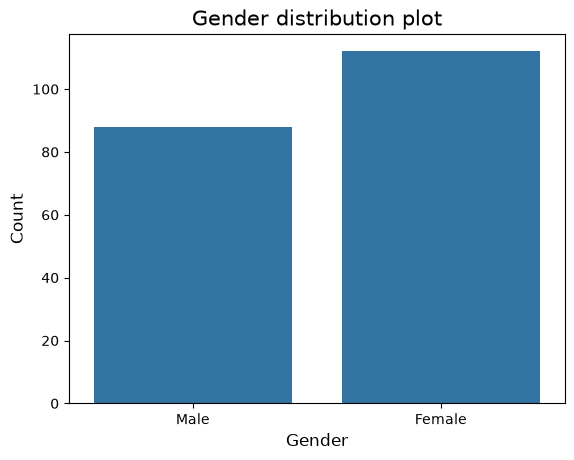

In [21]:
# Display the histogram
sns.countplot(x='gender', data=df)
plt.title('Gender distribution plot', fontsize=15)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

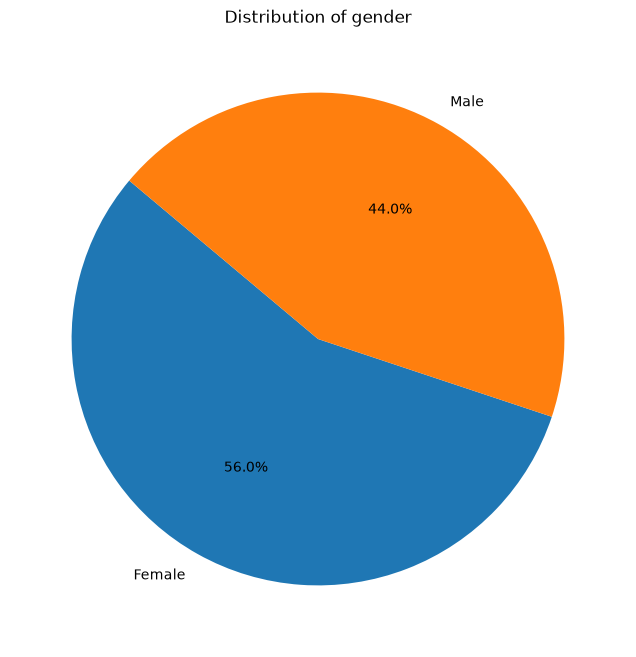

In [22]:
# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(value_counts.values, labels=value_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of gender')
plt.show()

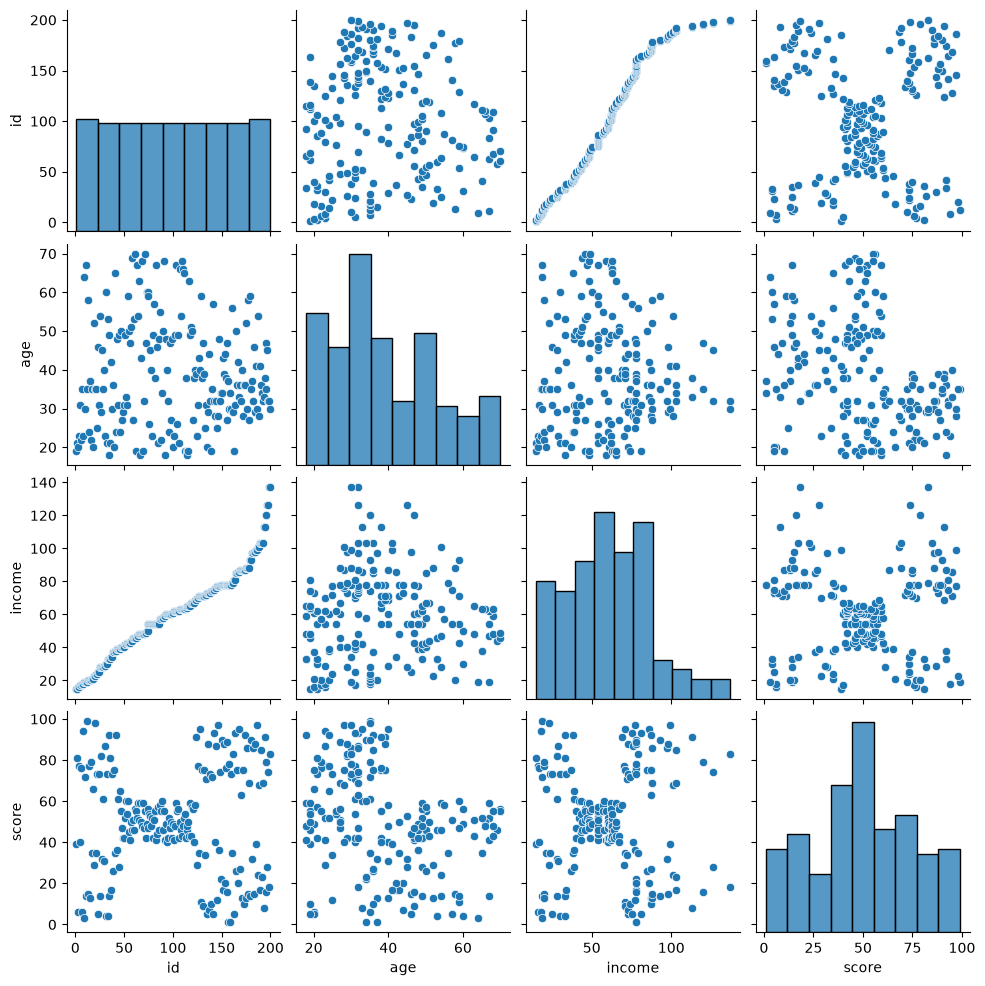

In [23]:
# Investigate the numerical variables
sns.pairplot(df)
plt.show()

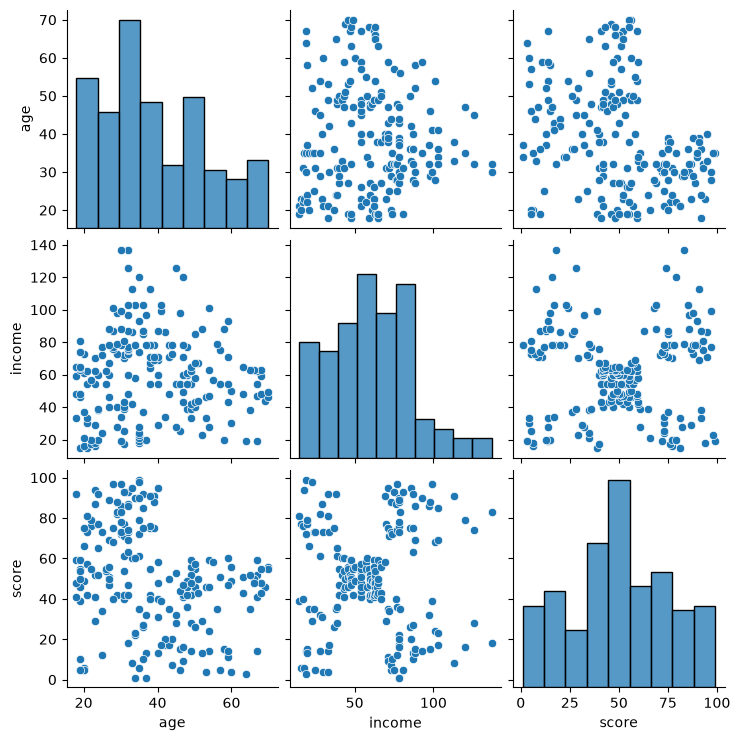

In [24]:
# P.S. The id variable is a unique identifier and is irrelevant
sns.pairplot(df[vars])
plt.show()

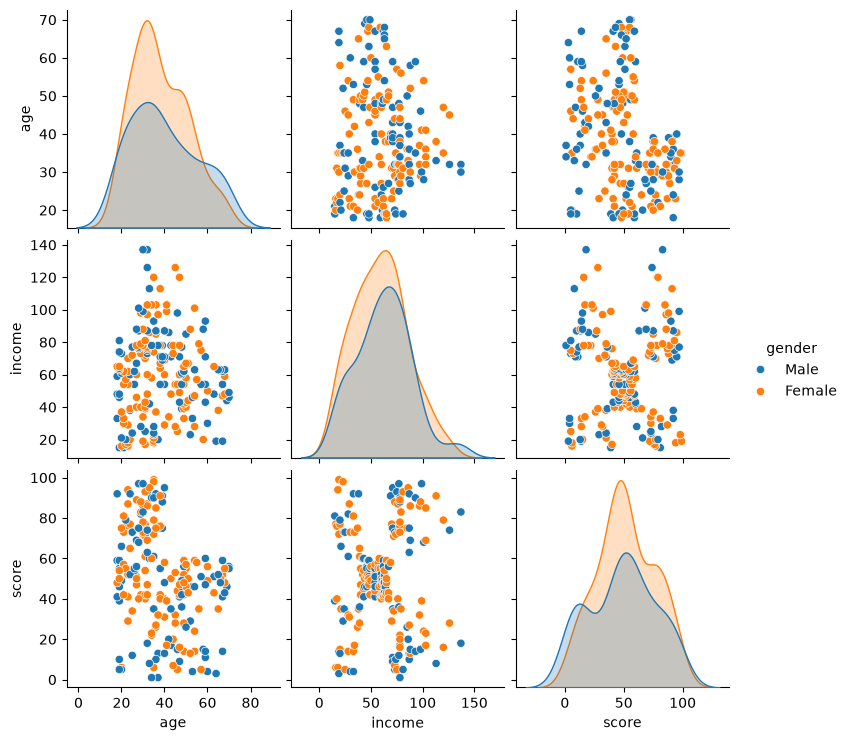

In [25]:
sns.pairplot(df[vars], hue='gender')
plt.show()

From the first pairplot, although id is irrelevant, from the scatter plot against income we learn that the dataset is sorted first by income, then each observation/row is given a unique id. 

From the histograms stratified by gender, we observe that there are similar patterns across age and income, albeit a higher concentration amongst females given that the dataset is biased towards that gender.

In the case of score, we observe that there is a similar median across genders, whereas the secondary spikes are on opposing sides per gender. 

From the other scatter plots we do not observe any divergence in patterns across gender. 

What is interesting and recommended for investigation is the absence of high spenders amongst the middle ages and elderly. 

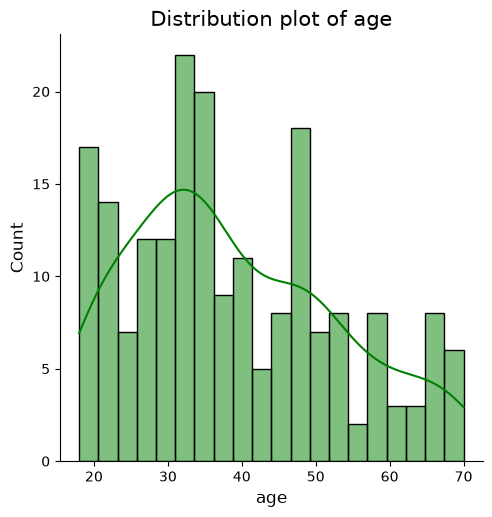

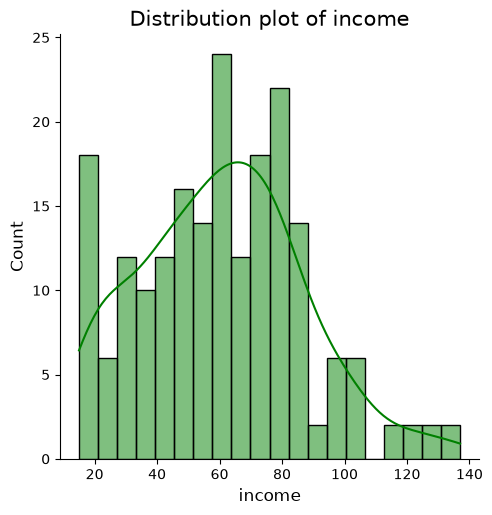

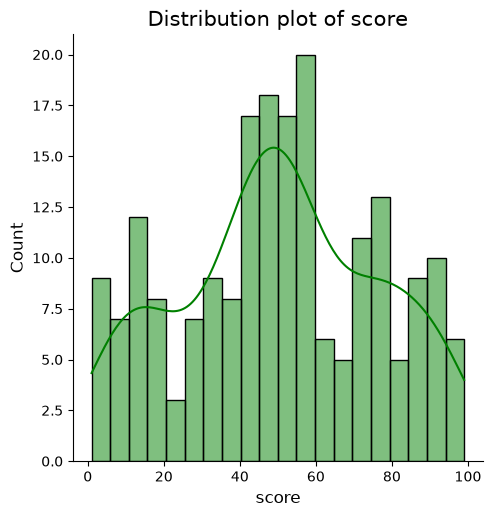

In [26]:
# Redefine the variables of interest
vars = ['age', 'income', 'score']

#Generate histograms
for feature in vars:
    sns.displot(x=df[feature], color='green', bins=20, kde=True)
    plt.title(f'Distribution plot of {feature}', fontsize=15)
    plt.xlabel(feature, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.show()

From the above histograms we note that the score feature is the one that approximates the most towards a normal distribution  curve. Appears to have like 3 groupings.

With regards to the income feature, it appears that there are some individuals that are very high income earners. Noting a break in the histogram we suspect that these might be anomalies. Therefore the need to investigate for outliers. 

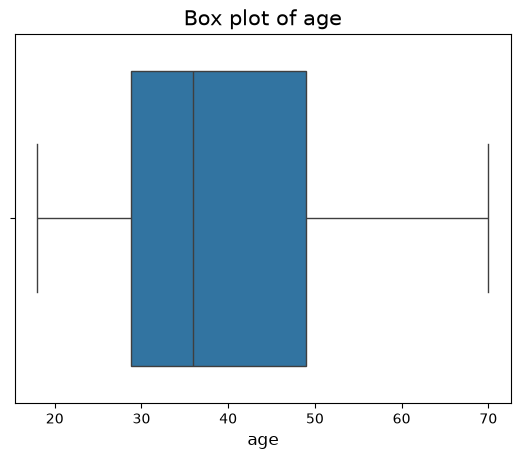

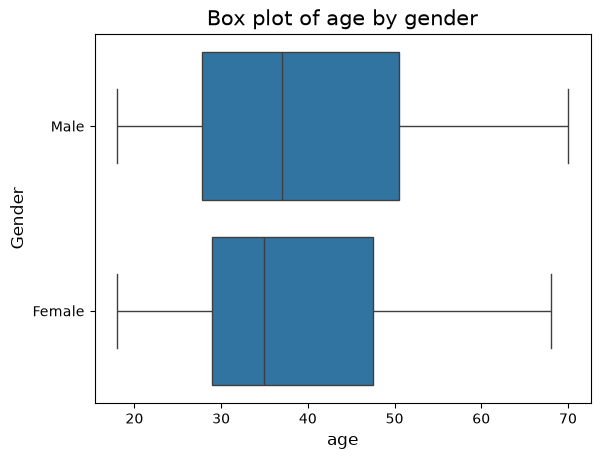

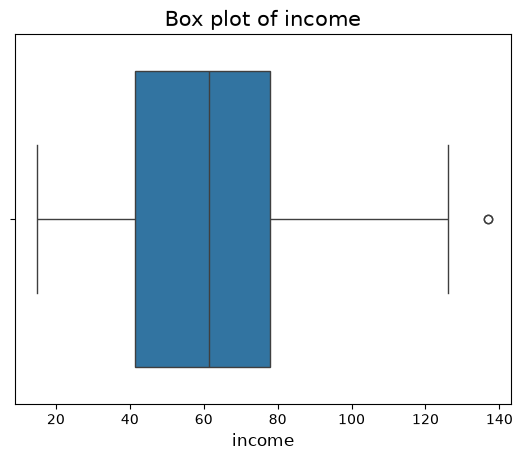

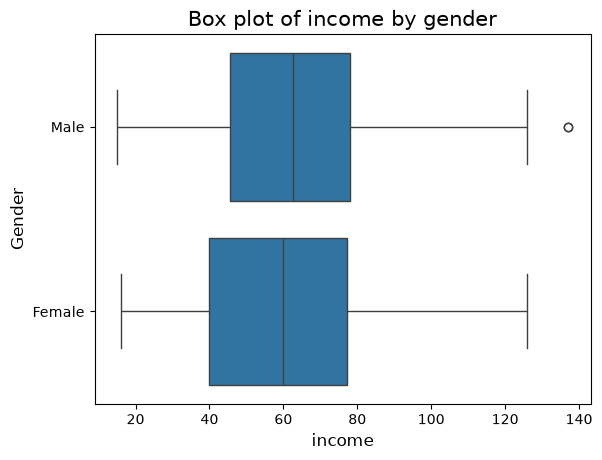

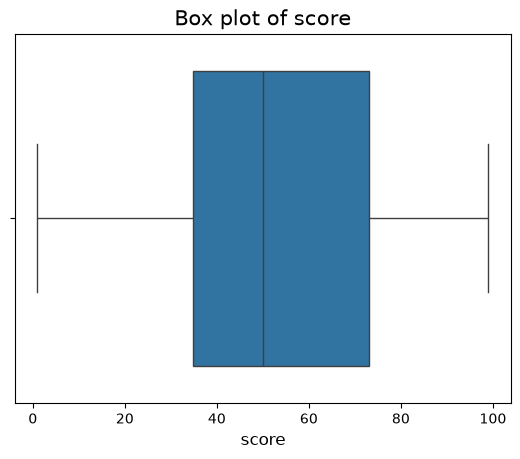

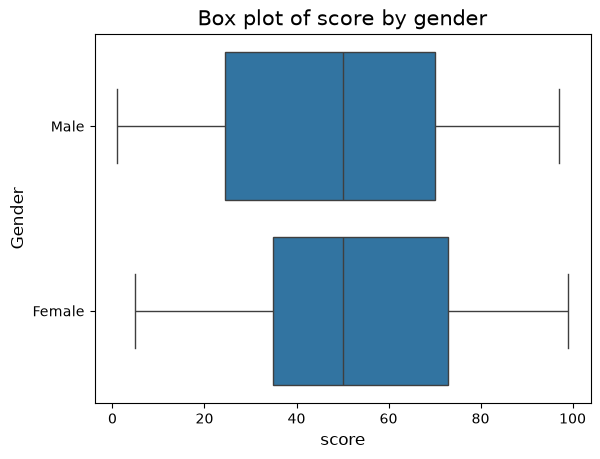

In [27]:
# Cycle through each feature in search of outliers
for feature in vars:
    sns.boxplot(x=df[feature])
    plt.title(f'Box plot of {feature}', fontsize=15)
    plt.xlabel(feature, fontsize=12)
    plt.show()

    sns.boxplot(x=df[feature], y=df['gender'])
    plt.title(f'Box plot of {feature} by gender', fontsize=15)
    plt.xlabel(feature, fontsize=12)
    plt.ylabel('Gender', fontsize=12)
    plt.show()

Following the boxplots, we confirm that there are outliers in the income feature, more specifically there are some male high earners that are outliers within this dataset. Recommending to further investigate these outliers to determine whether the case to exclude. 